In [1]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import *

In [2]:
data = pd.read_csv('../Data/temp_training.csv')

/var/folders/22/3z4yr_bd5ds4d1g7ph9nprs80000gn/T/ipykernel_50235/3943470689.py:1: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv('../Data/temp_training.csv')


In [3]:
data['log_asst_tot'] = np.log1p(data['asst_tot'])

In [5]:
result = precision_recall_by_bin(data, 'log_asst_tot')
result

,bin,records,defaults,population_share,precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(14.22, 14.361]",83335,1359,0.100000,1.63%,11.56%,1.63%,11.56%,1.156
1,"(14.361, 14.51]",83335,1252,0.100000,1.50%,10.65%,1.57%,22.22%,1.111
2,"(14.51, 14.674]",83335,1287,0.100000,1.54%,10.95%,1.56%,33.17%,1.106
3,"(14.674, 14.853]",83334,1209,0.099999,1.45%,10.29%,1.53%,43.46%,1.087
4,"(14.853, 15.056]",83335,1155,0.100000,1.39%,9.83%,1.50%,53.29%,1.066
5,"(15.056, 15.291]",83337,1111,0.100003,1.33%,9.45%,1.47%,62.74%,1.046
6,"(15.291, 15.582]",83332,1114,0.099997,1.34%,9.48%,1.45%,72.22%,1.032
7,"(15.582, 15.967]",83335,1169,0.100000,1.40%,9.95%,1.45%,82.17%,1.027
8,"(15.967, 16.577]",83335,1099,0.100000,1.32%,9.35%,1.43%,91.52%,1.017
9,"(16.577, 24.995]",83335,996,0.100000,1.20%,8.48%,1.41%,100.00%,1.000


In [ ]:
def calculate_iv(df, feature, target="default", n_bins=10, smoothing=0.5):
    data = df[[feature, target]].dropna(subset=[target]).copy()

    values = data[feature]

    if pd.api.types.is_numeric_dtype(values) and values.nunique() > 1:
        bins = pd.qcut(values, q=n_bins, duplicates="drop")

        # Quantile edges can collapse when many values are identical
        if len(bins.cat.categories) == 0: data["bin"] = "All observed"
        else: data["bin"] = bins.astype(object)
    else:
        # Categorical features, constants, or entirely missing features
        data["bin"] = values.astype(object)

    # Missingness is its own bin
    missing_label = "__MISSING__"
    while data["bin"].dropna().eq(missing_label).any():
        missing_label += "_"

    data.loc[values.isna(), "bin"] = missing_label

    table = (
        data.groupby("bin", observed=True, sort=False)[target]
        .agg(records="size", defaults="sum")
        .reset_index()
    )

    table["non_defaults"] = table["records"] - table["defaults"]

    k = len(table)
    total_defaults = table["defaults"].sum()
    total_non_defaults = table["non_defaults"].sum()

    # Additive smoothing; each distribution still sums to one
    table["default_dist"] = (
        (table["defaults"] + smoothing) /
        (total_defaults + smoothing * k)
    )
    table["non_default_dist"] = (
        (table["non_defaults"] + smoothing) /
        (total_non_defaults + smoothing * k)
    )

    # Convention: positive WoE indicates relatively more non-defaults
    table["woe"] = np.log(
        table["non_default_dist"] / table["default_dist"]
    )

    table["iv_component"] = (
        (table["non_default_dist"] - table["default_dist"])
        * table["woe"]
    )

    table["default_rate"] = table["defaults"] / table["records"]
    iv = table["iv_component"].sum()

    return iv, table

In [ ]:
data['default'].mean()

np.float64(0.014100951823247911)

In [ ]:
display(result.style.format({
    # "population_share": "{:.1%}",
    # "precision": "{:.2%}",
    # "recall": "{:.1%}"
}))

,bin,records,defaults,population_share,precision (%),recall (%),precision (cumm),recall (cumm),lift,lift (cumm)
0,"(14.22, 14.361]",83335,1359,0.100000,1.631%,11.565%,0.016308,0.115650,1.156495,1.156495
1,"(14.361, 14.51]",83335,1252,0.100000,1.502%,10.654%,0.015666,0.222194,1.065439,1.110967
2,"(14.51, 14.674]",83335,1287,0.100000,1.544%,10.952%,0.015592,0.331716,1.095223,1.105719
3,"(14.674, 14.853]",83334,1209,0.099999,1.451%,10.288%,0.015321,0.434601,1.028858,1.086504
4,"(14.853, 15.056]",83335,1155,0.100000,1.386%,9.829%,0.015029,0.532891,0.982893,1.065782
5,"(15.056, 15.291]",83337,1111,0.100003,1.333%,9.455%,0.014746,0.627436,0.945426,1.045722
6,"(15.291, 15.582]",83332,1114,0.099997,1.337%,9.480%,0.014549,0.722236,0.948036,1.031767
7,"(15.582, 15.967]",83335,1169,0.100000,1.403%,9.948%,0.014484,0.821717,0.994807,1.027147
8,"(15.967, 16.577]",83335,1099,0.100000,1.319%,9.352%,0.014340,0.915241,0.935237,1.016935
9,"(16.577, 24.995]",83335,996,0.100000,1.195%,8.476%,0.014101,1.000000,0.847585,1.000000


In [ ]:
# temp['def_date'] = temp['def_date'].astype(str)
temp['stmt_date'] = temp['stmt_date'].astype(str)

temp['def_date'].dropna().max(), temp['stmt_date'].max()

('2013-05-31', '2011-12-31')

In [ ]:
mapping = pickle.load(open('../Files/column_mapping.pkl', 'rb'))

In [ ]:
mapping['asset_cols']

['asst_intang_fixed',
 'asst_tang_fixed',
 'asst_fixed_fin',
 'asst_current',
 'AR',
 'cash_and_equiv',
 'asst_tot',
 'goodwill']

In [ ]:
df_filt = df[mapping['asset_cols'] + ['default','data_type']]
df_filt

,asst_intang_fixed,asst_tang_fixed,asst_fixed_fin,asst_current,AR,cash_and_equiv,asst_tot,goodwill,default,data_type
0,67537.0,1137566.0,1908.0,733496.0,283013.0,2083.0,1946940.0,157436.0,0,oot
1,256438.0,1181416.0,860.0,622992.0,387653.0,5339.0,2077346.0,253845.0,0,train
2,194046.0,1152014.0,860.0,615252.0,388260.0,10492.0,1975874.0,238817.0,0,train
3,126603.0,1127807.0,620.0,484753.0,455224.0,14279.0,1769122.0,363557.0,0,train
4,130973.0,1136731.0,946.0,609723.0,280395.0,6528.0,1897604.0,164637.0,0,test
...,...,...,...,...,...,...,...,...,...,...
833343,1498628.0,248233.0,163477.0,5344865.0,5344243.0,622.0,7648851.0,7885956.0,0,oot
833344,2465065.0,343015.0,43477.0,2955420.0,2955276.0,144.0,6223862.0,5408857.0,0,train
833345,2375606.0,261775.0,28642.0,3079088.0,3044484.0,34605.0,6146110.0,4134865.0,0,train
833346,2973.0,1131586.0,264600.0,148612.0,118835.0,29777.0,1547771.0,-4795.0,0,test


In [ ]:
df_filt = df_filt.sort_values(by='default')
df_filt

,asst_intang_fixed,asst_tang_fixed,asst_fixed_fin,asst_current,AR,cash_and_equiv,asst_tot,goodwill,default,data_type
0,67537.0,1137566.0,1908.0,733496.0,283013.0,2083.0,1946940.0,157436.0,0,oot
551094,290964.0,187651.0,0.0,5740454.0,4207530.0,27910.0,6232192.0,1687575.0,0,train
551095,1096126.0,568155.0,5000.0,11661633.0,7747969.0,210189.0,13362429.0,1404927.0,0,test
551096,811527.0,441066.0,109600.0,11727714.0,7124358.0,339738.0,13218027.0,2780354.0,0,oot
551097,622752.0,345725.0,509796.0,8779593.0,6091290.0,27730.0,10268839.0,1264613.0,0,train
...,...,...,...,...,...,...,...,...,...,...
779969,43332.0,1895410.0,0.0,2983289.0,1365722.0,982200.0,4924247.0,1032208.0,1,train
789143,57378.0,8907033.0,5995236.0,16449290.0,13587884.0,1774281.0,31591518.0,5387061.0,1,train
779971,0.0,32357.0,0.0,1972702.0,637564.0,19883.0,2035540.0,224410.0,1,train
779958,561.0,5879936.0,71.0,1274746.0,789.0,147132.0,7159108.0,-70220.0,1,train


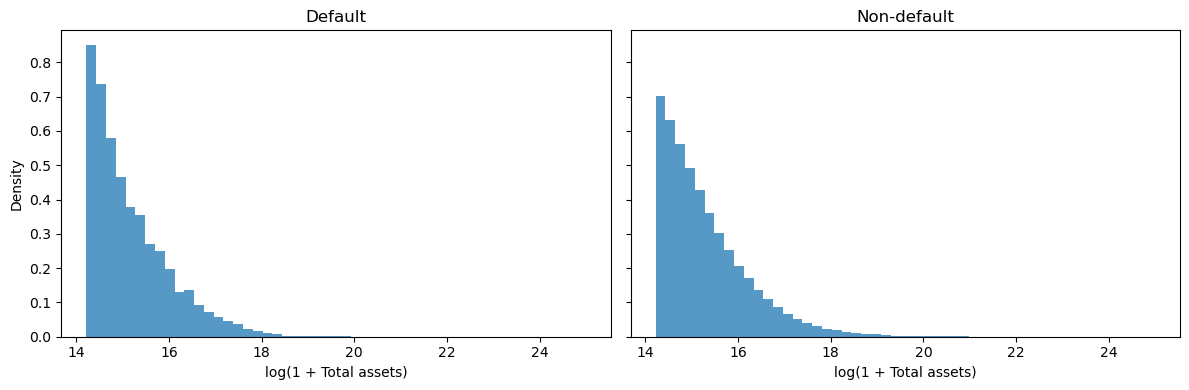

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)

bins = np.histogram_bin_edges(
    np.log1p(df_filt["asst_tot"].dropna()), bins=51
)
for ax, label in zip(axes, [1, 0]):
    values = np.log1p(
        df_filt.loc[df_filt["default"] == label, "asst_tot"].dropna()
    )
    ax.hist(values, bins=bins, density=True, alpha=0.75)
    ax.set_title("Default" if label == 1 else "Non-default")
    ax.set_xlabel("log(1 + Total assets)")

axes[0].set_ylabel("Density")
plt.tight_layout()
plt.show()

In [ ]:
df_filt['AR'].isna().sum()

np.int64(12)

In [ ]:
temp = df_filt[['AR','default','data_type']]
temp['feat'] = np.log1p(temp['AR'])
# plt.hist(temp['feat'])

/opt/homebrew/Caskroom/miniconda/base/envs/nlp/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/homebrew/Caskroom/miniconda/base/envs/nlp/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
/var/folders/22/3z4yr_bd5ds4d1g7ph9nprs80000gn/T/ipykernel_40092/1395079036.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  temp['feat'] = np.log1p(temp['AR'])


/opt/homebrew/Caskroom/miniconda/base/envs/nlp/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/homebrew/Caskroom/miniconda/base/envs/nlp/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


ValueError: supplied range of [-inf, 22.96945918694506] is not finite

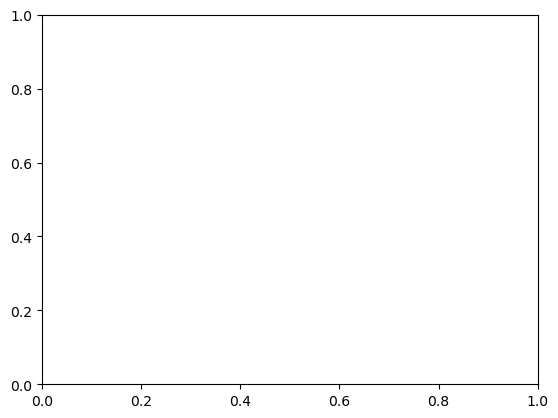

In [ ]:
plt.hist(np.log1p(df_filt.query('default == 0')['AR']))
plt.hist(np.log1p(df_filt.query('default == 1')['AR']))